import

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

dataset
UIC Injections

In [17]:
# Указываем путь к вашему CSV-файлу
file_path = 'data/uic_injection_volumes_2011_2019.csv'

# Загружаем датасет
try:
    df = pd.read_csv(file_path)
    print("Файл успешно загружен!")
except FileNotFoundError:
    print(f"Ошибка: файл не найден по пути '{file_path}'. Проверьте расположение файла.")
    exit()

# 1. Первые 3 рядка
print("\n=== 1. Первые 3 рядка датасета ===")
print(df.head(3))

# 2. Размеры датасета
print("\n=== 2. Размеры датасета ===")
print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")

# 3. Проверка на пустые строки / пропущенные значения
print("\n=== 3. Пропущенные значения по столбцам ===")
missing = df.isnull().sum()
if missing.sum() > 0:
    print(missing[missing > 0])
else:
    print("В датасете нет пропущенных значений.")

# 4. Базовый анализ (типы данных и статистика)
print("\n=== 4. Информация о типах данных ===")
print(df.info())

print("\n=== 5. Базовая статистическая сводка ===")
print(df.describe(include='all'))

Файл успешно загружен!

=== 1. Первые 3 рядка датасета ===
   Year         API               OperatorName                  WellName  \
0  2011  3500300026      PHOENIX PETROCORP INC  SE EUREKA UNIT-TUCKER #1   
1  2011  3500300163    SUPERIOR PRODUCTION LLC               CHRISTENSEN   
2  2011  3500320145  CONTINENTAL RESOURCES INC                   SINGREE   

  WellNumber Status WellStatus WellType        LAT        LON  ...  Aug Vol  \
0         21   OPEN         AC     2RIn  36.900396 -98.219252  ...      0.0   
1          1   OPEN         AC     2RIn  36.896636 -98.177720  ...   1132.0   
2          1   OPEN         PA       TM  36.504849 -98.433240  ...  12929.0   

   Aug PSI Sep Vol Sep PSI  Oct Vol Oct PSI Nov Vol Nov PSI  Dec Vol  Dec PSI  
0      0.0     0.0     0.0      0.0     0.0     0.0     0.0      0.0      0.0  
1    200.0  1132.0   200.0   1296.0   250.0  1063.0   200.0    920.0    250.0  
2    100.0     0.0   250.0  20192.0   100.0  2982.0   100.0  18067.0    100.0  

Preskúmajte a analyzujte pridelené dáta tak, aby ste dokázali opísať ich obsah, charakteristiky, priestorové a časové vlastnosti, identifikovať zaujímavé vzory a závislosti a na základe vykonanej analýzy vysvetliť, čo sa v dátach deje a aké závery z nich možno vyvodiť.
1. <br>
2. <br>
3. <br>
4. <br>
5. <br>
6. <br>
7. <br>
8. <br>
9. <br>
10. <br>

In [18]:
# 1. Подготовка временного ряда

months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

volume_columns = [f'{month} Vol' for month in months]

# Переводим месяцы из отдельных столбцов в строки
volume_long = df.melt(
    id_vars=['API', 'Year'],
    value_vars=volume_columns,
    var_name='month',
    value_name='volume'
)

# Название месяца: "Jan Vol" -> "Jan"
volume_long['month'] = volume_long['month'].str.replace(
    ' Vol', '', regex=False
)

# Номер месяца
month_numbers = {month: number for number, month in enumerate(months, start=1)}
volume_long['month_number'] = volume_long['month'].map(month_numbers)

# Создаём дату: первое число каждого месяца
volume_long['date'] = pd.to_datetime(
    dict(
        year=volume_long['Year'],
        month=volume_long['month_number'],
        day=1
    )
)

# Агрегируем данные по всем скважинам
monthly = (
    volume_long
    .groupby('date')
    .agg(
        total_volume=('volume', 'sum'),
        mean_volume=('volume', 'mean'),
        number_of_records=('volume', 'count')
    )
    .sort_index()
)

print(monthly.head())
print(monthly.tail())

            total_volume   mean_volume  number_of_records
date                                                     
2011-01-01  1.635255e+08  15735.706126              10392
2011-02-01  1.448641e+08  13939.962077              10392
2011-03-01  1.687305e+08  16236.574843              10392
2011-04-01  1.622064e+08  15608.772211              10392
2011-05-01  1.675129e+08  16119.409684              10392
            total_volume   mean_volume  number_of_records
date                                                     
2019-08-01   163300974.0  14376.351263              11359
2019-09-01   164399716.0  14473.080025              11359
2019-10-01   172283879.0  15167.169557              11359
2019-11-01   161778826.0  14242.347566              11359
2019-12-01   167208721.0  14720.373360              11359


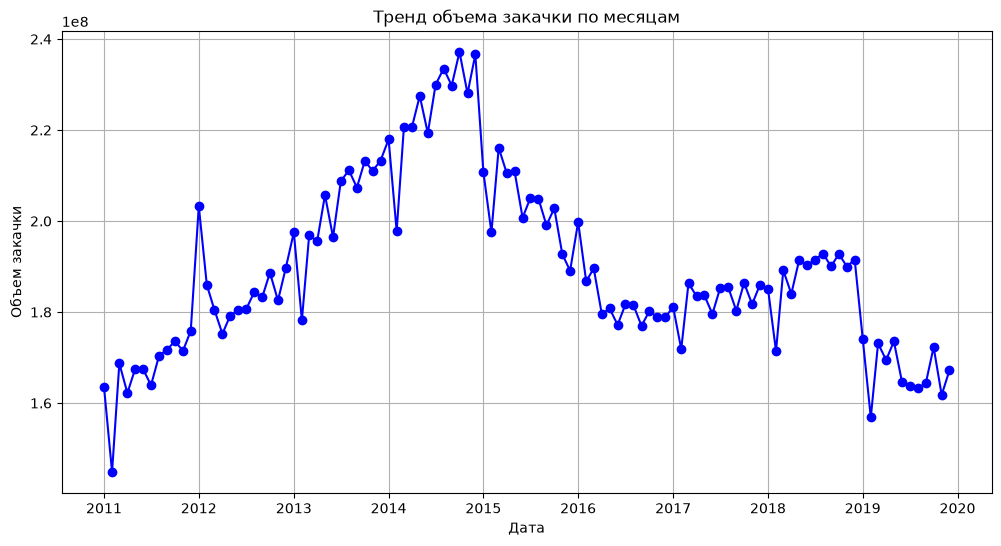

month           Jan           Feb           Mar           Apr           May  \
Year                                                                          
2011   1.635255e+08  1.448641e+08  1.687305e+08  1.622064e+08  1.675129e+08   
2012   2.032712e+08  1.859461e+08  1.805358e+08  1.752073e+08  1.792410e+08   
2013   1.975362e+08  1.781670e+08  1.968353e+08  1.956200e+08  2.057221e+08   
2014   2.179522e+08  1.977932e+08  2.206724e+08  2.207053e+08  2.275127e+08   
2015   2.107928e+08  1.975065e+08  2.161153e+08  2.105216e+08  2.109780e+08   

month           Jun           Jul           Aug           Sep           Oct  \
Year                                                                          
2011   1.673970e+08  1.639178e+08  1.704003e+08  1.717493e+08  1.736051e+08   
2012   1.804721e+08  1.805727e+08  1.843197e+08  1.832127e+08  1.886538e+08   
2013   1.964693e+08  2.087616e+08  2.111702e+08  2.073664e+08  2.131589e+08   
2014   2.193252e+08  2.299674e+08  2.335274e+08  2.

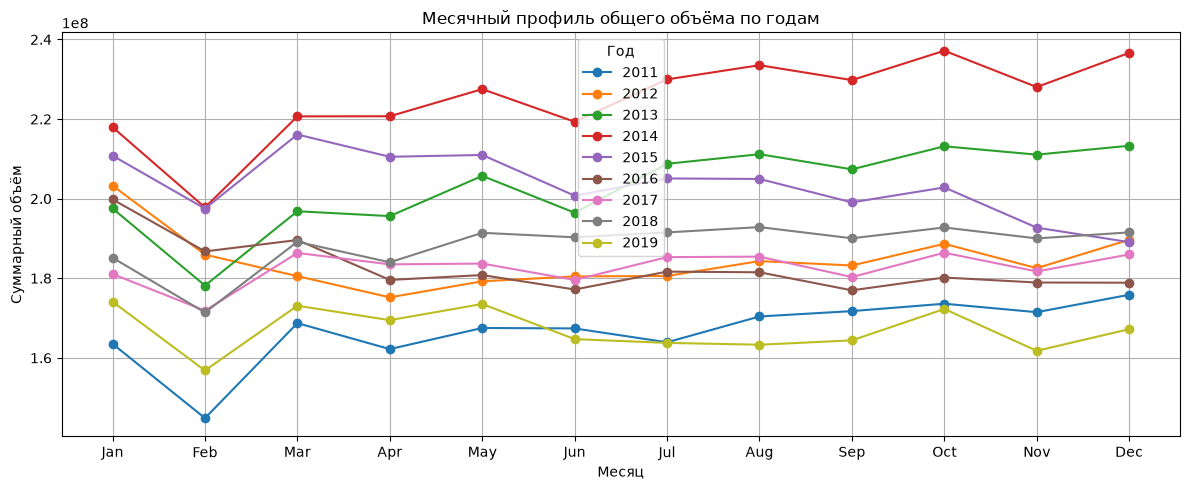

In [19]:
# 2. Тренд и сезонность
plt.figure(figsize=(12, 6))
plt.plot(monthly.index, monthly['total_volume'], marker='o', linestyle='-', color='blue')
plt.title('Тренд объема закачки по месяцам')
plt.xlabel('Дата')
plt.ylabel('Объем закачки')
plt.grid(True)
plt.show()

seasonal_table = (
    volume_long
    .groupby(['Year', 'month'])['volume']
    .sum()
    .unstack()
    .reindex(columns=months)
)

print(seasonal_table.head())

plt.figure(figsize=(12, 5))

for year in seasonal_table.index:
    plt.plot(
        months,
        seasonal_table.loc[year],
        marker='o',
        label=str(year)
    )

plt.title('Месячный профиль общего объёма по годам')
plt.xlabel('Месяц')
plt.ylabel('Суммарный объём')
plt.legend(title='Год')
plt.grid(True)
plt.tight_layout()
plt.show()

date
2011-01-01    1.635255e+08
2011-02-01    1.448641e+08
2011-03-01    1.687305e+08
2011-04-01    1.622064e+08
2011-05-01    1.675129e+08
Freq: MS, Name: total_volume, dtype: float64
DatetimeIndex(['2011-01-01', '2011-02-01', '2011-03-01', '2011-04-01',
               '2011-05-01', '2011-06-01', '2011-07-01', '2011-08-01',
               '2011-09-01', '2011-10-01',
               ...
               '2019-03-01', '2019-04-01', '2019-05-01', '2019-06-01',
               '2019-07-01', '2019-08-01', '2019-09-01', '2019-10-01',
               '2019-11-01', '2019-12-01'],
              dtype='datetime64[us]', name='date', length=108, freq='MS')


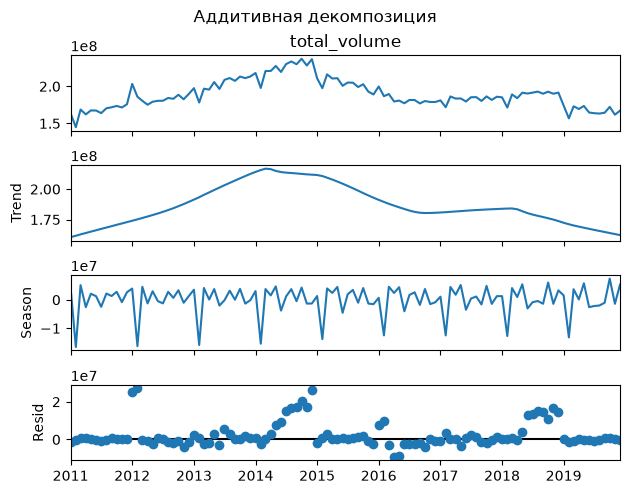

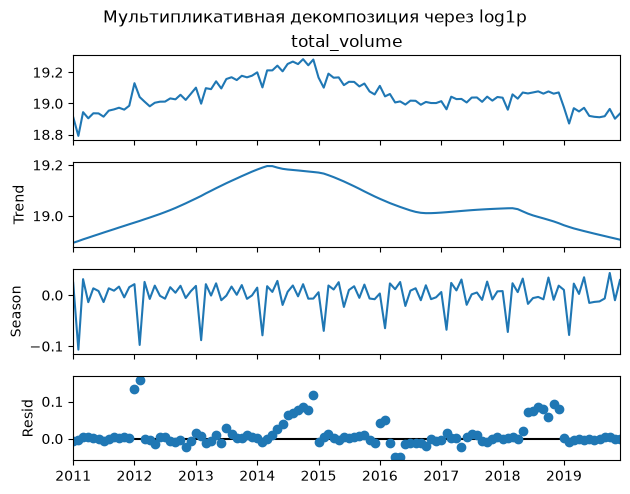

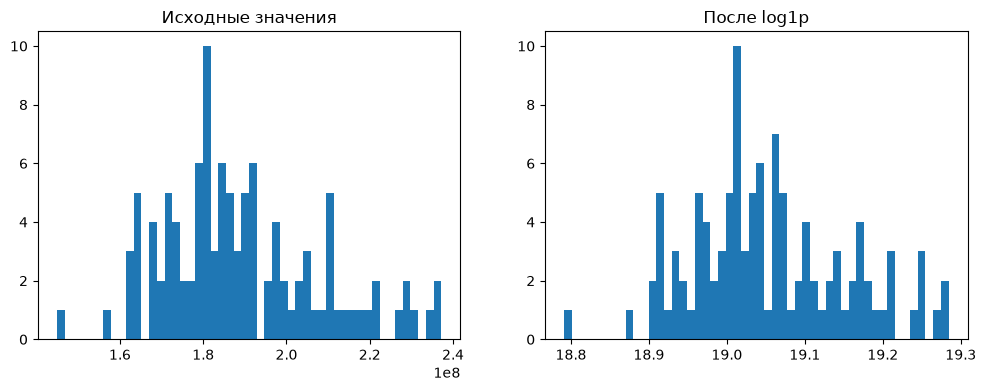

In [20]:
# 3. Аддитивная и мультипликативная сезонность

# Временной ряд суммарного месячного объёма
series = monthly['total_volume'].copy()

# Проверяем порядок дат
series = series.sort_index()

# Устанавливаем месячную частоту
series_complete = series.asfreq('MS')

# Заполняем возможные пропущенные месяцы
series_complete = series_complete.interpolate()

print(series_complete.head())
print(series_complete.index)

# Аддитивная декомпозиция

stl_additive = STL(
    series_complete,
    period=12,
    robust=True
).fit()

stl_additive.plot()
plt.suptitle('Аддитивная декомпозиция', y=1.02)
plt.show()

log_series = np.log1p(series_complete)

stl_multiplicative = STL(
    log_series,
    period=12,
    robust=True
).fit()

stl_multiplicative.plot()
plt.suptitle('Мультипликативная декомпозиция через log1p', y=1.02)
plt.show()


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(series_complete, bins=50)
plt.title('Исходные значения')

plt.subplot(1, 2, 2)
plt.hist(np.log1p(series_complete), bins=50)
plt.title('После log1p')

plt.show()

              mean           std  median    min        max
Year                                                      
2011  16047.945153  49650.317428  3516.5 -434.0  1781945.0
2012  16919.267318  56899.501688  3304.0    0.0  2528313.0
2013  18416.350825  57644.110659  3660.0    0.0  2042348.0
2014  19936.457877  63348.712609  3800.0    0.0  2089704.0
2015  18617.997619  58382.249532  3548.0    0.0  1986359.0
2016  16458.507528  45315.948932  2848.5    0.0  1370947.0
2017  16192.417406  43099.661186  2615.0    0.0  1057307.0
2018  16821.262273  65623.200948  2504.0 -500.0  4013325.0
2019  14705.742819  42349.673471  1766.5    0.0  3660088.0


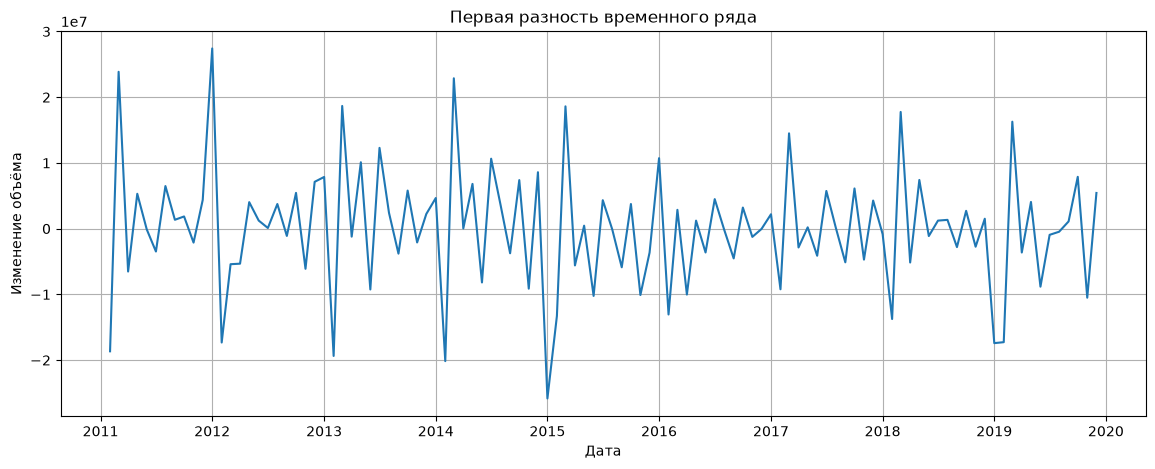

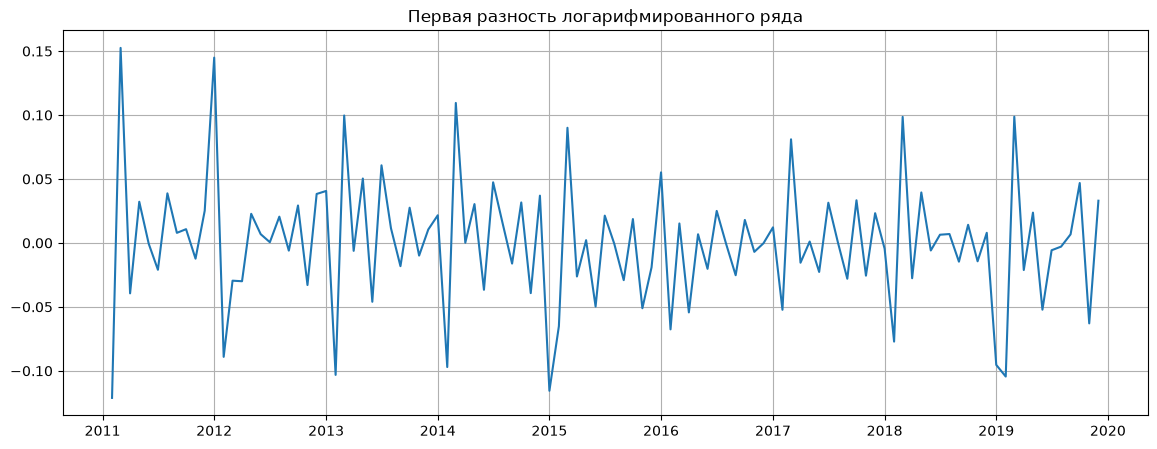

In [21]:
# 4. Стационарность

year_statistics = (
    volume_long
    .groupby('Year')['volume']
    .agg(['mean', 'std', 'median', 'min', 'max'])
)

print(year_statistics)

series_diff = series_complete.diff().dropna()

plt.figure(figsize=(14, 5))
plt.plot(series_diff)
plt.title('Первая разность временного ряда')
plt.xlabel('Дата')
plt.ylabel('Изменение объёма')
plt.grid()
plt.show()


log_diff = log_series.diff().dropna()

plt.figure(figsize=(14, 5))
plt.plot(log_diff)
plt.title('Первая разность логарифмированного ряда')
plt.grid()
plt.show()

In [22]:
# 5. Тесты стационарности ADF и KPSS


def stationarity_tests(data, name):
    data = data.dropna()

    adf_result = adfuller(data, autolag='AIC')
    kpss_result = kpss(data, regression='c', nlags='auto')

    print(f'\n{name}')
    print('-' * 40)

    print(f'ADF statistic: {adf_result[0]:.4f}')
    print(f'ADF p-value: {adf_result[1]:.4f}')

    print(f'KPSS statistic: {kpss_result[0]:.4f}')
    print(f'KPSS p-value: {kpss_result[1]:.4f}')

    if adf_result[1] < 0.05:
        print('ADF: ряд можно считать стационарным')
    else:
        print('ADF: нет оснований считать ряд стационарным')

    if kpss_result[1] > 0.05:
        print('KPSS: ряд можно считать стационарным')
    else:
        print('KPSS: ряд, вероятно, нестационарный')


stationarity_tests(series_complete, 'Исходный ряд')
stationarity_tests(series_diff, 'Первая разность')


Исходный ряд
----------------------------------------
ADF statistic: -1.1396
ADF p-value: 0.6990
KPSS statistic: 0.3992
KPSS p-value: 0.0775
ADF: нет оснований считать ряд стационарным
KPSS: ряд можно считать стационарным

Первая разность
----------------------------------------
ADF statistic: -2.6530
ADF p-value: 0.0825
KPSS statistic: 0.2772
KPSS p-value: 0.1000
ADF: нет оснований считать ряд стационарным
KPSS: ряд можно считать стационарным


C:\Users\Денис\AppData\Local\Temp\ipykernel_24744\3791772014.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(data, autolag='AIC')
C:\Users\Денис\AppData\Local\Temp\ipykernel_24744\3791772014.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(data, regression='c', nlags='auto')
C:\Users\Де

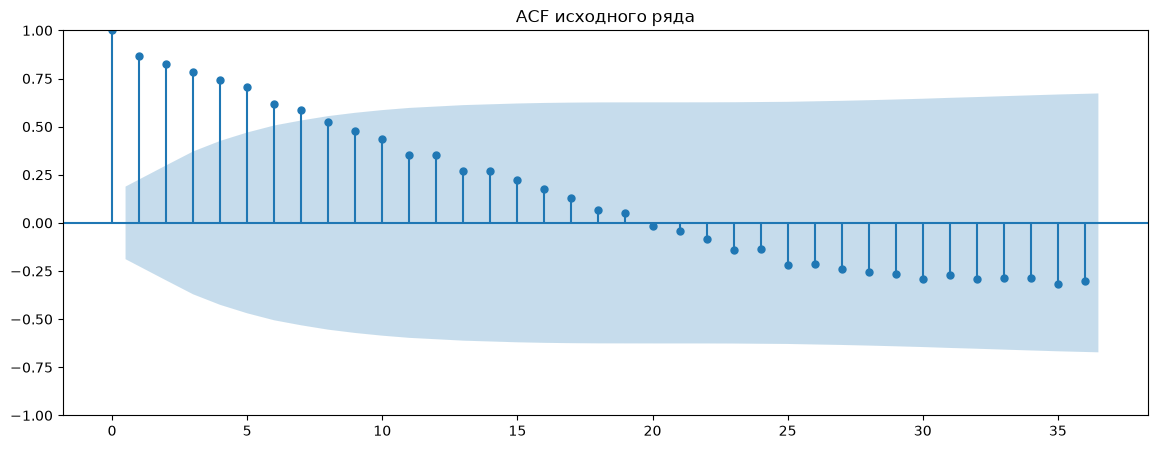

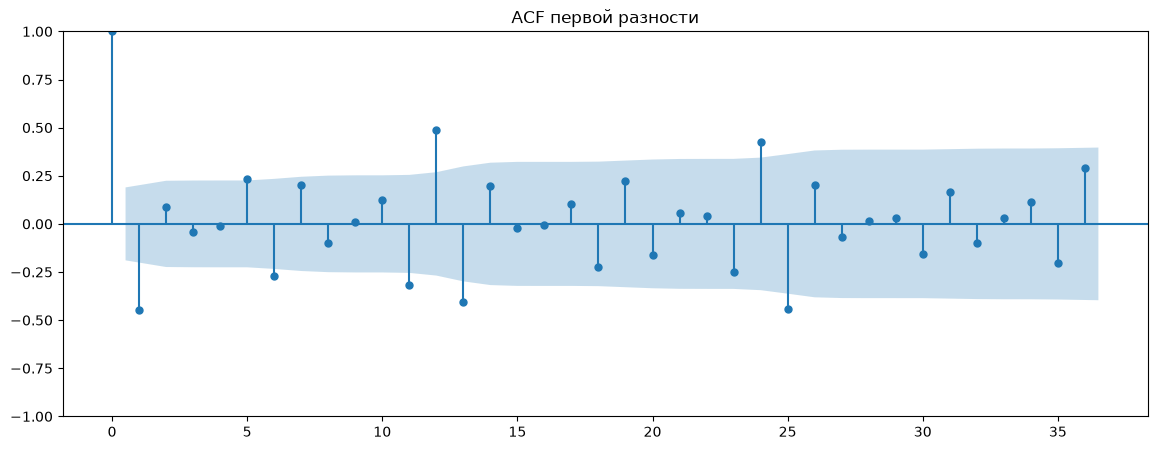

Лаг 1: 0.8809
Лаг 2: 0.8684
Лаг 3: 0.8322
Лаг 6: 0.6875
Лаг 12: 0.4111
Лаг 24: -0.2041
Лаг 36: -0.4345


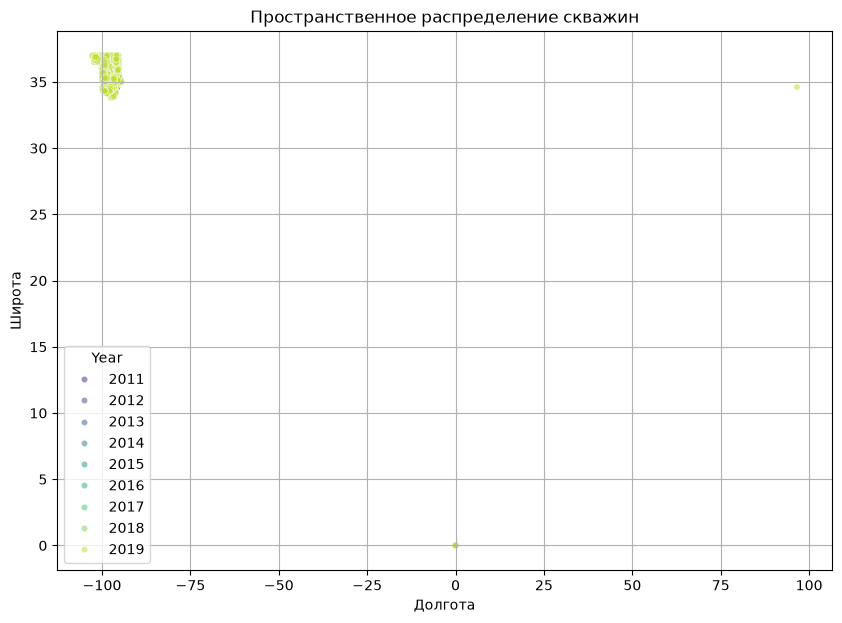

            wells  total_volume  average_latitude  average_longitude
County                                                              
CARTER       1955  2.806961e+08         34.314665         -97.457601
STEPHENS     1477  1.220110e+08         34.410991         -97.661970
CREEK        1085  1.229139e+08         35.919472         -96.357000
PONTOTOC      768  1.465274e+08         34.731786         -96.556152
SEMINOLE      566  9.892329e+07         35.127022         -96.591209
NOWATA        487  2.356032e+07         36.780812         -95.639262
TEXAS         420  5.242260e+07         36.815966        -101.565336
GARVIN        404  3.991505e+07         34.660880         -97.438291
WASHINGTON    390  8.523010e+06         36.772527         -95.880460
PAWNEE        306  2.000422e+07         36.238556         -96.517154


In [23]:
# 6. Автокорреляция


plt.figure(figsize=(14, 5))
plot_acf(
    series_complete.dropna(),
    lags=36,
    ax=plt.gca()
)
plt.title('ACF исходного ряда')
plt.show()

plt.figure(figsize=(14, 5))
plot_acf(
    series_diff,
    lags=36,
    ax=plt.gca()
)
plt.title('ACF первой разности')
plt.show()


for lag in [1, 2, 3, 6, 12, 24, 36]:
    print(
        f'Лаг {lag}: '
        f'{series_complete.autocorr(lag=lag):.4f}'
    )



spatial_data = df.dropna(subset=['LAT', 'LON', 'Year'])

spatial_data['Year'] = spatial_data['Year'].astype(str)

plt.figure(figsize=(10, 7))



sns.scatterplot(
    data=spatial_data,
    x='LON',
    y='LAT',
    hue='Year',
    palette='viridis',
    alpha=0.5,
    s=20
)

plt.title('Пространственное распределение скважин')
plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.grid()
plt.show()


county_statistics = (
    df.groupby('County')
    .agg(
        wells=('API', 'nunique'),
        total_volume=('Jan Vol', 'sum'),
        average_latitude=('LAT', 'mean'),
        average_longitude=('LON', 'mean')
    )
    .sort_values('wells', ascending=False)
)

print(county_statistics.head(10))

In [24]:
print('Все годы:')
print(sorted(df['Year'].dropna().unique()))

print('Годы после фильтрации:')
print(sorted(spatial_data['Year'].unique()))

print('Количество записей по годам:')
print(df['Year'].value_counts().sort_index())

print('Количество записей с координатами по годам:')
print(
    df.dropna(subset=['LAT', 'LON', 'Year'])
      .groupby('Year')
      .size()
)

Все годы:
[np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]
Годы после фильтрации:
['2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019']
Количество записей по годам:
Year
2011    10392
2012    10903
2013    11019
2014    11282
2015    10923
2016    11098
2017    11277
2018    11197
2019    11359
Name: count, dtype: int64
Количество записей с координатами по годам:
Year
2011    10392
2012    10902
2013    11019
2014    11282
2015    10923
2016    11098
2017    11277
2018    11197
2019    11351
dtype: int64


1.Implementujte a natrénujte prvý pridelený model na riešenie vhodne zvoleného problému, vyhodnoťte jeho výsledky a vysvetlite, ako model pracuje s priestorovými a časovými vlastnosťami dát, aké sú jeho výhody a obmedzenia.

 2. Implementujte a natrénujte druhý pridelený model na riešenie rovnakého problému, porovnajte jeho výsledky s prvým modelom a vysvetlite rozdiely medzi ich architektúrami.


CNN-LSTM - Implementácia, vedieť porovnať architektúru a výsledky s prvými dvoma modelmi

Analyzujte a porovnajte vplyv vtláčania priemyselných odpadových vôd na frekvenciu a intenzitu zemetrasení v priestore a čase v oblasti Oklahomy. Porovnajte presnosť predikcie modelov pri rozličnej intenzite vtláčania na vybraných dátach.
